In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
import tensorflow as tf
print("GPU available:", tf.config.list_physical_devices('GPU'))

I0000 00:00:1783435882.006025   30318 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import tensorflow.keras.backend as K
import tensorflow as tf

I0000 00:00:1783488825.470087     909 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
train_dir = 'data/Train'
test_dir  = 'data/Test'

CLASS_NAMES = sorted(os.listdir(train_dir))
print("Classes:", CLASS_NAMES)

Classes: ['Diseased', 'Healthy']


In [5]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

train_datagen = ImageDataGenerator(preprocessing_function=preprocess_input, validation_split=0.15)

train_gen = train_datagen.flow_from_directory(
    train_dir, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='binary', classes=CLASS_NAMES, subset='training', shuffle=True, seed=42
)
val_gen = train_datagen.flow_from_directory(
    train_dir, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='binary', classes=CLASS_NAMES, subset='validation', shuffle=False
)

test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)
test_gen = test_datagen.flow_from_directory(
    test_dir, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='binary', classes=CLASS_NAMES, shuffle=False
)

print("Class mapping:", train_gen.class_indices)

weights = compute_class_weight('balanced', classes=np.unique(train_gen.classes), y=train_gen.classes)
class_weights_dict = dict(enumerate(weights))
print("Class weights:", class_weights_dict)

Found 4760 images belonging to 2 classes.
Found 840 images belonging to 2 classes.
Found 1400 images belonging to 2 classes.
Class mapping: {'Diseased': 0, 'Healthy': 1}
Class weights: {0: np.float64(1.0), 1: np.float64(1.0)}


In [6]:
def build_mobilenet(fine_tune_last_n=0, learning_rate=1e-4):
    base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

    if fine_tune_last_n == 0:
        base_model.trainable = False
    else:
        base_model.trainable = True
        for layer in base_model.layers[:-fine_tune_last_n]:
            layer.trainable = False

    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.5)(x)
    x = Dense(128, activation='relu')(x)
    predictions = Dense(1, activation='sigmoid')(x)   # binary output

    model = Model(inputs=base_model.input, outputs=predictions)
    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model


In [7]:
def train_and_evaluate(model_name, model, epochs=30, patience=6):
    callbacks = [
        EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True),
        ModelCheckpoint(f'{model_name}.keras', monitor='val_loss', save_best_only=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-7)
    ]

    model.fit(
        train_gen,
        steps_per_epoch=train_gen.samples // train_gen.batch_size,
        validation_data=val_gen,
        validation_steps=val_gen.samples // val_gen.batch_size,
        epochs=epochs,
        class_weight=class_weights_dict,
        callbacks=callbacks
    )

    best_model = load_model(f'{model_name}.keras')

    test_gen.reset()
    y_true = test_gen.classes
    steps = int(np.ceil(test_gen.samples / test_gen.batch_size))
    y_pred_probs = best_model.predict(test_gen, steps=steps).flatten()
    y_pred = (y_pred_probs[:len(y_true)] > 0.5).astype(int)

    print(f"\n{'='*50}\n{model_name} -- TEST SET RESULTS\n{'='*50}")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap='Greens')
    plt.title(f'{model_name} -- Confusion Matrix')
    plt.show()

    return best_model

Epoch 1/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 44s 86ms/step - accuracy: 0.8904 - loss: 0.2633 - val_accuracy: 0.9591 - val_loss: 0.1187 - learning_rate: 1.0000e-04
Epoch 2/30
  1/297 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.8750 - loss: 0.1754

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8750 - loss: 0.1754 - val_accuracy: 0.9591 - val_loss: 0.1197 - learning_rate: 1.0000e-04
Epoch 3/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - accuracy: 0.9553 - loss: 0.1241 - val_accuracy: 0.9736 - val_loss: 0.0763 - learning_rate: 1.0000e-04
Epoch 4/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9375 - loss: 0.2088 - val_accuracy: 0.9736 - val_loss: 0.0762 - learning_rate: 1.0000e-04
Epoch 5/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 10s 35ms/step - accuracy: 0.9648 - loss: 0.0993 - val_accuracy: 0.9772 - val_loss: 0.0650 - learning_rate: 1.0000e-04
Epoch 6/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 1.0000 - loss: 0.0226 - val_accuracy: 0.9772 - val_loss: 0.0648 - learning_rate: 1.0000e-04
Epoch 7/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.9730 - loss: 0.0790 - val_accuracy: 0.9772 - val_loss: 0.0583 - learning_rate: 1.0000e-04
Epoch 8/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8750

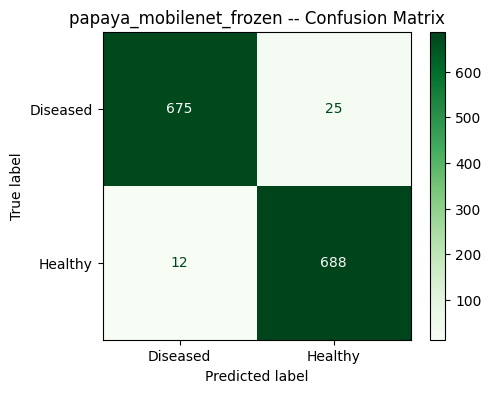

In [18]:
model_frozen = build_mobilenet(fine_tune_last_n=0)
model_frozen = train_and_evaluate('papaya_mobilenet_frozen', model_frozen)

I0000 00:00:1783435957.780150   30318 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Epoch 1/30


I0000 00:00:1783435961.603231   30318 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1783435972.286475   30843 service.cc:153] XLA service 0x4b7e8030 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1783435972.286550   30843 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6 (Driver: 13.1.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.24.0)
I0000 00:00:1783435972.580640   30843 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1783435974.870638   30843 cuda_dnn.cc:461] Loaded cuDNN version 92400
I0000 00:00:1783435975.163705   30843 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_13317__.159
I0000 00:00:1783435999.063231   30843 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process

206/297 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.7897 - loss: 0.4471

I0000 00:00:1783436010.616954   30844 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_13317__.159


297/297 ━━━━━━━━━━━━━━━━━━━━ 78s 136ms/step - accuracy: 0.8314 - loss: 0.3758 - val_accuracy: 0.9339 - val_loss: 0.1800 - learning_rate: 1.0000e-05
Epoch 2/30
  1/297 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - accuracy: 0.9375 - loss: 0.2119

/home/shlok/Projects/Potato Leaf Disease Detection/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


297/297 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9375 - loss: 0.2119 - val_accuracy: 0.9363 - val_loss: 0.1793 - learning_rate: 1.0000e-05
Epoch 3/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - accuracy: 0.9490 - loss: 0.1464 - val_accuracy: 0.9675 - val_loss: 0.0939 - learning_rate: 1.0000e-05
Epoch 4/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 1.0000 - loss: 0.0885 - val_accuracy: 0.9675 - val_loss: 0.0939 - learning_rate: 1.0000e-05
Epoch 5/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - accuracy: 0.9656 - loss: 0.0956 - val_accuracy: 0.9820 - val_loss: 0.0571 - learning_rate: 1.0000e-05
Epoch 6/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9375 - loss: 0.0649 - val_accuracy: 0.9820 - val_loss: 0.0570 - learning_rate: 1.0000e-05
Epoch 7/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - accuracy: 0.9789 - loss: 0.0693 - val_accuracy: 0.9856 - val_loss: 0.0410 - learning_rate: 1.0000e-05
Epoch 8/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.93

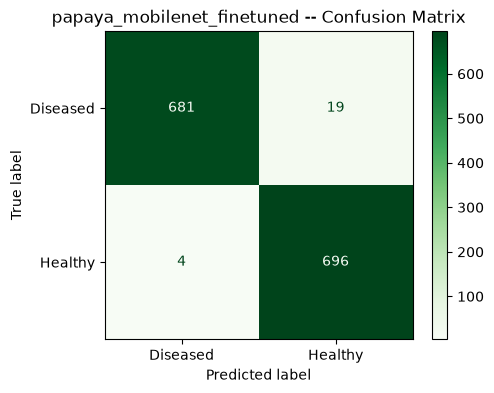

In [10]:
K.clear_session()
train_gen.reset(); val_gen.reset(); test_gen.reset()

model_ft = build_mobilenet(fine_tune_last_n=30, learning_rate=1e-5)
model_ft = train_and_evaluate('papaya_mobilenet_finetuned', model_ft)

In [8]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

def print_full_precision_metrics(y_true, y_pred, model_name, class_names):
    acc = accuracy_score(y_true, y_pred)
    f1_macro = f1_score(y_true, y_pred, average='macro')
    f1_weighted = f1_score(y_true, y_pred, average='weighted')
    precision_macro = precision_score(y_true, y_pred, average='macro')
    recall_macro = recall_score(y_true, y_pred, average='macro')

    print(f"\n{model_name} ")
    print(f"Accuracy:            {acc:.6f}  ({acc*100:.4f}%)")
    print(f"F1 (macro):          {f1_macro:.6f}")
    print(f"F1 (weighted):       {f1_weighted:.6f}")
    print(f"Precision (macro):   {precision_macro:.6f}")
    print(f"Recall (macro):      {recall_macro:.6f}")


    f1_per_class = f1_score(y_true, y_pred, average=None)
    for cls, f1_val in zip(class_names, f1_per_class):
        print(f"  F1 [{cls}]:         {f1_val:.6f}")

In [12]:
test_gen.reset()
y_true = test_gen.classes
steps = int(np.ceil(test_gen.samples / test_gen.batch_size))
y_pred_probs = model_ft.predict(test_gen, steps=steps).flatten()
y_pred = (y_pred_probs[:len(y_true)] > 0.5).astype(int)

print_full_precision_metrics(y_true, y_pred, 'papaya_mobilenet_finetuned', CLASS_NAMES)

88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step

papaya_mobilenet_finetuned 
Accuracy:            0.983571  (98.3571%)
F1 (macro):          0.983570
F1 (weighted):       0.983570
Precision (macro):   0.983794
Recall (macro):      0.983571
  F1 [Diseased]:         0.983394
  F1 [Healthy]:         0.983746


In [9]:
model_ft = tf.keras.models.load_model("papaya_mobilenet_finetuned.keras")

I0000 00:00:1783489106.362601     909 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


In [11]:
def predict_external_images(model, model_name, preprocess_fn, target_size, external_dir, class_names_ordered):
    valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp')

    print(f"\n{model_name}")

    class_dirs = [
        os.path.join(external_dir, class_name)
        for class_name in class_names_ordered
        if os.path.isdir(os.path.join(external_dir, class_name))
    ]

    if class_dirs:
        for class_name in class_names_ordered:
            class_dir = os.path.join(external_dir, class_name)
            if not os.path.isdir(class_dir):
                continue

            for fname in os.listdir(class_dir):
                if not fname.lower().endswith(valid_extensions):
                    continue

                img_path = os.path.join(class_dir, fname)
                try:
                    img = load_img(img_path, target_size=target_size)
                    arr = img_to_array(img)
                    arr = preprocess_fn(arr.copy())
                    arr = np.expand_dims(arr, axis=0)

                    prob = model.predict(arr, verbose=0)[0][0]
                    pred_idx = int(prob > 0.5)
                    predicted_class = class_names_ordered[pred_idx]
                    confidence = prob if pred_idx == 1 else (1 - prob)

                    print(f"[True: {class_name:10s} -> Predicted: {predicted_class:10s} ({confidence*100:.2f}% confidence)")

                except Exception as e:
                    print(f"Could not process {fname}: {e}")
    else:
        for fname in os.listdir(external_dir):
            if not fname.lower().endswith(valid_extensions):
                continue

            img_path = os.path.join(external_dir, fname)
            try:
                img = load_img(img_path, target_size=target_size)
                arr = img_to_array(img)
                arr = preprocess_fn(arr.copy())
                arr = np.expand_dims(arr, axis=0)

                prob = model.predict(arr, verbose=0)[0][0]
                pred_idx = int(prob > 0.5)
                predicted_class = class_names_ordered[pred_idx]
                confidence = prob if pred_idx == 1 else (1 - prob)

                print(f"[{fname}] -> Predicted: {predicted_class:10s} ({confidence*100:.2f}% confidence)")

            except Exception as e:
                print(f"Could not process {fname}: {e}")

In [17]:
external_test_dir = 'healthy papaya'

predict_external_images(model_ft, 'Papaya_MobileNet_FineTuned', preprocess_input, (224, 224),
                         external_test_dir, CLASS_NAMES)


Papaya_MobileNet_FineTuned
[main3.jpg] -> Predicted: Healthy    (99.99% confidence)
[h4.png] -> Predicted: Diseased   (98.78% confidence)
[main4.jpg] -> Predicted: Healthy    (99.99% confidence)
[main1.jpg] -> Predicted: Healthy    (93.15% confidence)
[h2.png] -> Predicted: Diseased   (99.32% confidence)
[h1.png] -> Predicted: Diseased   (97.65% confidence)
[h3.png] -> Predicted: Diseased   (100.00% confidence)
[main2.jpg] -> Predicted: Healthy    (99.64% confidence)


#### Important Insights

- The **h_i** images were taken from the internet to test from the external data. But due to different lightning and real-world image issue, model faced difficulty to intepret it correctly.
- Where as the **main_i** images were taken from the https://shorturl.at/Csa6l the images were made for the disease detection purpose, and we can clearly see that our model performed very well.

In [18]:
import cv2

def show_gradcam_binary(model, img_path, preprocess_fn, target_size, class_names_ordered, last_conv_layer_name=None):
    img = load_img(img_path, target_size=target_size)
    img_array = img_to_array(img)
    img_array_batch = np.expand_dims(preprocess_fn(img_array.copy()), axis=0)

    # Auto-detect the last conv layer ONLY if none was specified
    if last_conv_layer_name is None:
        for layer in reversed(model.layers):
            try:
                shape = layer.output.shape
                if len(shape) == 4:
                    last_conv_layer_name = layer.name
                    break
            except AttributeError:
                continue

    if last_conv_layer_name is None:
        raise ValueError("Could not find a 4D conv layer in this model.")

    grad_model = Model(model.inputs, [model.get_layer(last_conv_layer_name).output, model.output])

    _, plain_predictions = grad_model(img_array_batch, training=False)
    prob_value = float(plain_predictions.numpy()[0][0])
    pred_idx = int(prob_value > 0.5)

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array_batch, training=False)
        loss = predictions[:, 0] if pred_idx == 1 else -predictions[:, 0]

    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    heatmap = heatmap.numpy()

    heatmap_resized = cv2.resize(heatmap, target_size)
    heatmap_uint8 = np.uint8(255 * heatmap_resized)
    heatmap_colored = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)

    superimposed = np.uint8(np.clip(img_array * 0.6 + heatmap_colored * 0.4, 0, 255))

    predicted_class = class_names_ordered[pred_idx]
    confidence = prob_value if pred_idx == 1 else (1 - prob_value)

    fig, axes = plt.subplots(1, 3, figsize=(14, 5))
    axes[0].imshow(img_array.astype('uint8')); axes[0].set_title('Original'); axes[0].axis('off')
    axes[1].imshow(heatmap_resized, cmap='jet'); axes[1].set_title(f'Grad-CAM ({last_conv_layer_name})'); axes[1].axis('off')
    axes[2].imshow(superimposed); axes[2].set_title(f'Overlay -- Predicted: {predicted_class} ({confidence*100:.1f}%)'); axes[2].axis('off')
    plt.tight_layout()
    plt.show()

/home/shlok/Projects/Potato Leaf Disease Detection/.venv/lib/python3.12/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


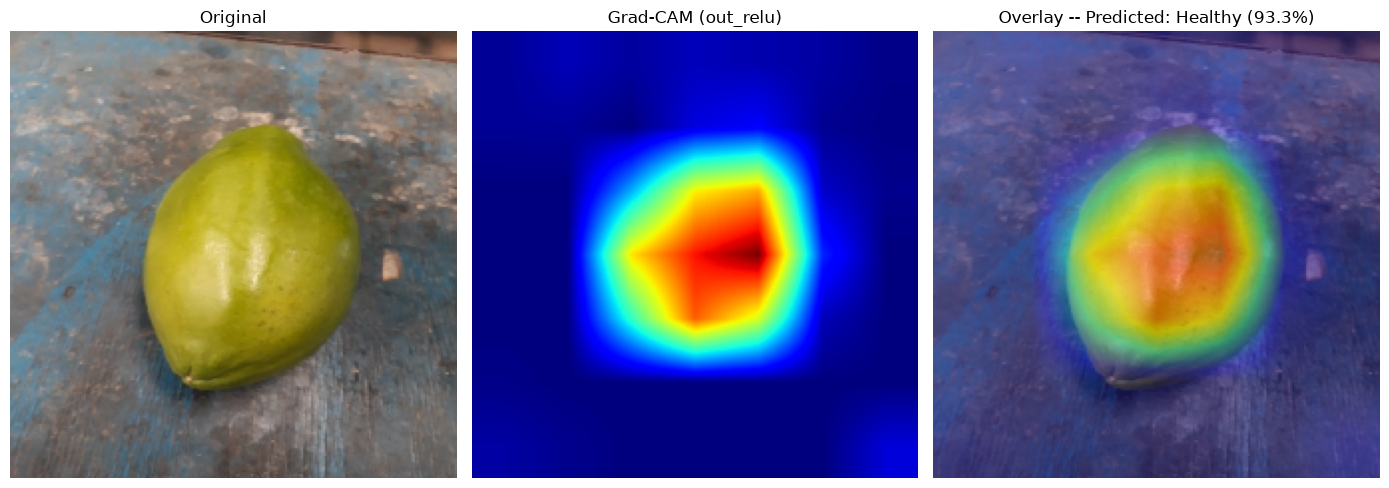

In [19]:
show_gradcam_binary(model_ft, 'healthy papaya/main1.jpg',
                     preprocess_input, (224, 224), CLASS_NAMES)

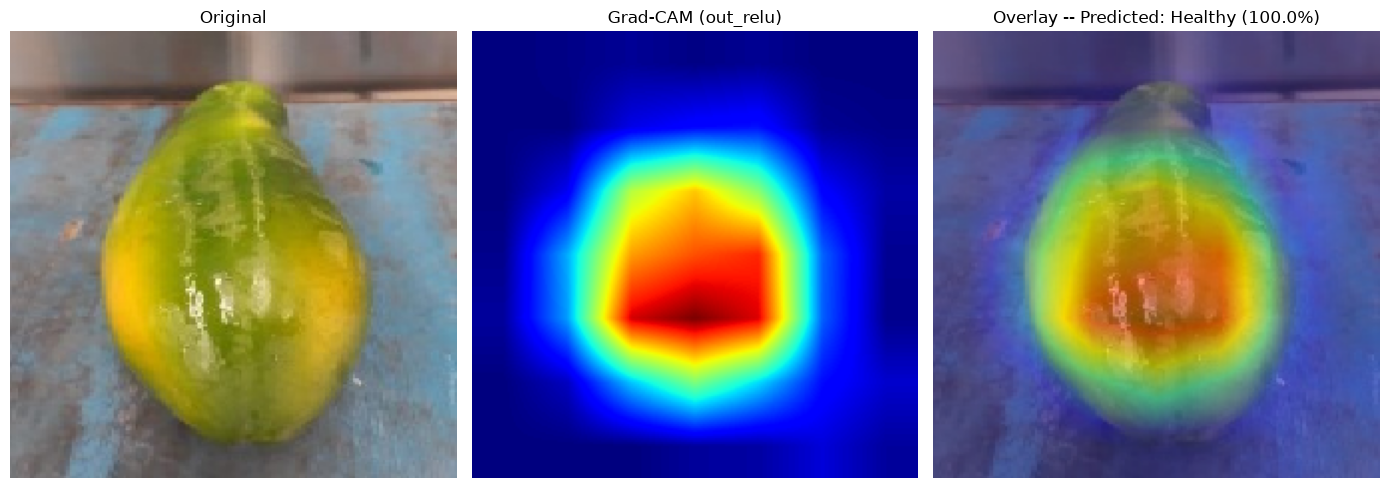

In [28]:
show_gradcam_binary(model_ft, 'healthy papaya/main3.jpg',
                     preprocess_input, (224, 224), CLASS_NAMES)